<a href="https://colab.research.google.com/github/kristinamishugova-alt/MashineLearning/blob/main/MashineLearning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Проект: Регрессионный анализ стоимости автомобилей

0. Введение и постановка задачи.
Цель данной работы — построить модель машинного обучения, способную предсказывать рыночную стоимость автомобиля (переменная Price / price).
Это классическая задача регрессии. В качестве основного алгоритма будет использован метод k-ближайших соседей для регрессии (KNeighborsRegressor). Проходится весь цикл: от очистки данных до оценки итогового качества прогноза.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.preprocessing import MinMaxScaler
from sklearn.impute import SimpleImputer
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import Lasso
from sklearn.dummy import DummyRegressor
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score
import warnings
warnings.filterwarnings("ignore")
sns.set_context("notebook")
sns.set_style("darkgrid")

1. Загрузка датасета и базовый осмотр.
Считается файл с данными об автомобилях. Сразу привожу названия колонок к нижнему регистру для удобства обращения и посмотрим на размерность таблицы.

In [ ]:
cars_df = pd.read_csv('automobile_dataset.csv')
cars_df.columns = cars_df.columns.str.lower()
print(f"Количество записей: {cars_df.shape[0]}")
print(f"Количество признаков: {cars_df.shape[1]}")
display(cars_df.head(6))
display(cars_df.describe(include='number').round(1))

Количество записей: 5500
Количество признаков: 18


,make,model,year,fuel_type,transmission,engine_size,mileage,horsepower,torque,owners,accident_history,service_history,color,body_type,drivetrain,fuel_efficiency,location,selling_price
0,Mercedes-Benz,GLE,2024,Petrol,Automatic,2.3,100,186.0,196.0,1,0.0,NaN,Silver,SUV,AWD,30.0,IL,64140
1,Hyundai,Tucson,2008,Petrol,Automatic,2.3,387035,189.0,190.0,4,0.0,NaN,Blue,SUV,FWD,35.0,FL,500
2,Volkswagen,Golf,2021,Hybrid,NaN,1.9,46054,158.0,153.0,1,0.0,Partial Service,Gray,Hatchback,AWD,43.0,NY,16429
3,Chevrolet,Tahoe,2005,Petrol,NaN,2.2,141302,169.0,165.0,5,1.0,No Service,Blue,SUV,AWD,NaN,FL,2199
4,Toyota,Camry,2022,Petrol,Automatic,1.9,32813,149.0,141.0,1,0.0,Full Service,Brown,Sedan,FWD,38.0,CA,21792
5,Chevrolet,Equinox,2008,Petrol,NaN,2.7,60654,212.0,207.0,3,0.0,NaN,Blue,SUV,AWD,25.0,TX,3421


,year,engine_size,mileage,horsepower,torque,owners,accident_history,fuel_efficiency,selling_price
count,5500.0,4656.0,5500.0,4700.0,4701.0,5500.0,4688.0,4706.0,5500.0
mean,2014.5,2.5,114529.5,198.2,189.0,2.5,0.4,34.2,12319.9
std,5.8,0.8,91858.9,55.7,56.6,1.3,0.5,15.1,12658.5
min,2005.0,0.0,100.0,97.0,77.0,1.0,0.0,10.0,500.0
25%,2009.0,2.0,39112.0,160.0,151.0,1.0,0.0,27.0,1304.8
50%,2014.0,2.4,96926.5,187.0,178.0,2.0,0.0,32.0,8586.0
75%,2020.0,3.0,172757.5,231.0,219.0,3.0,1.0,37.0,19097.5
max,2024.0,5.7,536731.0,434.0,443.0,5.0,1.0,141.0,86692.0


2. Очистка целевой переменной (selling_price).
В датасете с автомобилями $1 означает ошибку парсинга или продажу по запчастям. Оставляю только адекватные значения — автомобили дороже 500 единиц.

Размер датасета после фильтрации целевой переменной: 4284


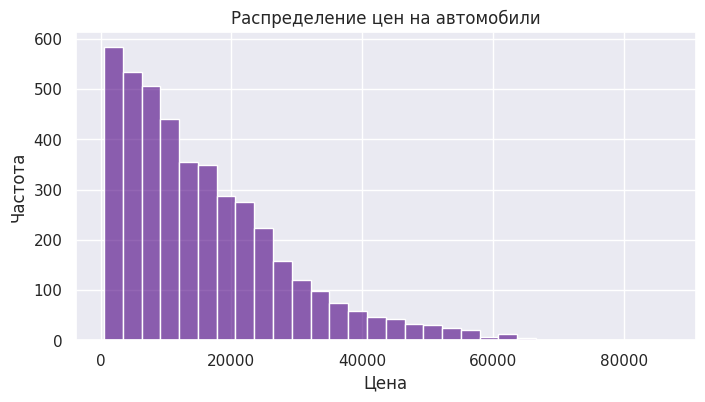

In [ ]:
target_col = 'selling_price'
cars_df = cars_df[cars_df[target_col] > 500].copy()
cars_df.reset_index(drop=True, inplace=True)
print(f"Размер датасета после фильтрации целевой переменной: {cars_df.shape[0]}")
plt.figure(figsize=(8, 4))
sns.histplot(cars_df[target_col], bins=30, color='indigo', alpha=0.6)
plt.title('Распределение цен на автомобили')
plt.xlabel('Цена')
plt.ylabel('Частота')
plt.show()

№3. Feature Engineering и удаление утечек.


1. Создаю признак "Возраст автомобиля" (car_age) на основе года выпуска.
2. Удаляю колонку года (чтобы не дублировать информацию) и колонки названия конкретной модели или VIN-номера, так как их слишком много, и для метода k-ближайщих сосодей это превратится в шум.

In [ ]:
if 'year' in cars_df.columns:
    cars_df['car_age'] = 2024 - cars_df['year']
    cars_df.drop(columns=['year'], inplace=True)
cols_to_drop = ['id', 'vin', 'model', 'title', 'description', 'url']
existing_drops = [c for c in cols_to_drop if c in cars_df.columns]
cars_df.drop(columns=existing_drops, inplace=True)

display(cars_df.head(6))

,make,fuel_type,transmission,engine_size,mileage,horsepower,torque,owners,accident_history,service_history,color,body_type,drivetrain,fuel_efficiency,location,selling_price,car_age
0,Mercedes-Benz,Petrol,Automatic,2.3,100,186.0,196.0,1,0.0,NaN,Silver,SUV,AWD,30.0,IL,64140,0
1,Volkswagen,Hybrid,NaN,1.9,46054,158.0,153.0,1,0.0,Partial Service,Gray,Hatchback,AWD,43.0,NY,16429,3
2,Chevrolet,Petrol,NaN,2.2,141302,169.0,165.0,5,1.0,No Service,Blue,SUV,AWD,NaN,FL,2199,19
3,Toyota,Petrol,Automatic,1.9,32813,149.0,141.0,1,0.0,Full Service,Brown,Sedan,FWD,38.0,CA,21792,2
4,Chevrolet,Petrol,NaN,2.7,60654,212.0,207.0,3,0.0,NaN,Blue,SUV,AWD,25.0,TX,3421,16
5,Nissan,Petrol,Automatic,2.2,7444,NaN,180.0,1,0.0,Full Service,Gray,Sedan,AWD,34.0,IL,17145,2


4. Разделение данных на Train и Test.
Отделяю целевую переменную от признаков. Разбиваю выборку в пропорции 75% на 25%. Делаю это сейчас, чтобы все последующие преобразования (заполнение пропусков, кодирование) обучались только на тренировочном наборе.

In [ ]:
target = cars_df[target_col]
features = cars_df.drop(columns=[target_col])
X_tr, X_te, y_tr, y_te = train_test_split(features, target, test_size=0.25, random_state=21)
print(f"Размер обучающего набора (Train): {X_tr.shape[0]}")
print(f"Размер тестового набора (Test): {X_te.shape[0]}")

Размер обучающего набора (Train): 3213
Размер тестового набора (Test): 1071


 5. Разведочный анализ (EDA) обучающей выборки.
Смотрю, как зависят цены от пробега и возраста. Делаю матрицу корреляций для числовых признаков.

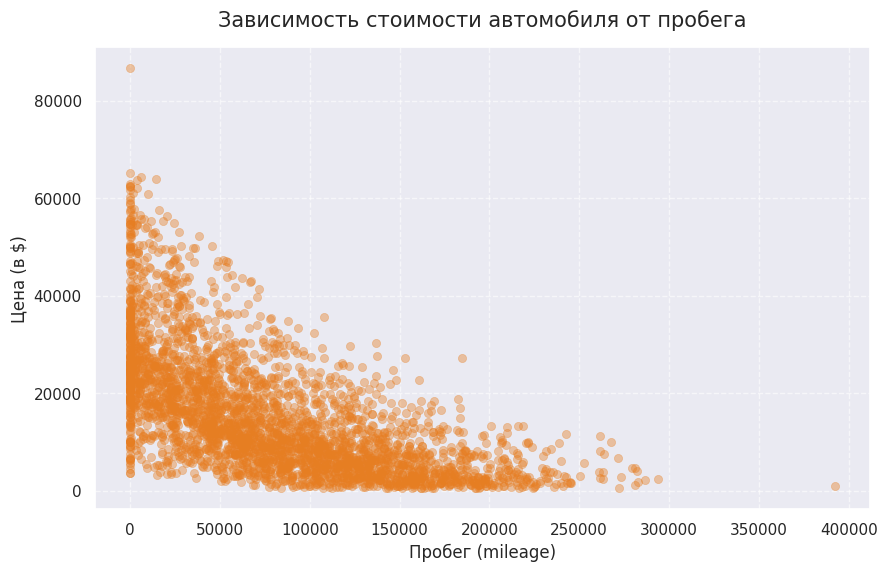

In [ ]:
eda_df = X_tr.copy()
eda_df['TARGET_PRICE'] = y_tr
plt.figure(figsize=(10, 6))
if 'mileage' in eda_df.columns:
    sns.scatterplot(x='mileage', y='TARGET_PRICE', data=eda_df,
                    alpha=0.4, color='#E67E22', edgecolor=None, s=35)

    plt.title('Зависимость стоимости автомобиля от пробега', fontsize=15, pad=15)
    plt.xlabel('Пробег (mileage)', fontsize=12)
    plt.ylabel('Цена (в $)', fontsize=12)
    plt.grid(True, linestyle='--', alpha=0.6)

plt.show()

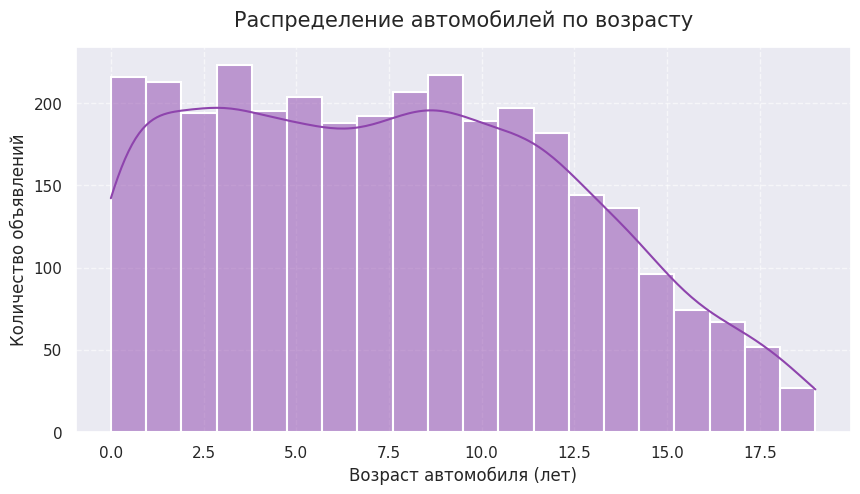

In [ ]:
plt.figure(figsize=(10, 5))
if 'car_age' in eda_df.columns:
    sns.histplot(eda_df['car_age'], bins=20, kde=True,
                 color='#8E44AD', edgecolor='white', linewidth=1.5)

    plt.title('Распределение автомобилей по возрасту', fontsize=15, pad=15)
    plt.xlabel('Возраст автомобиля (лет)', fontsize=12)
    plt.ylabel('Количество объявлений', fontsize=12)
    plt.grid(True, linestyle='--', alpha=0.6)

plt.show()

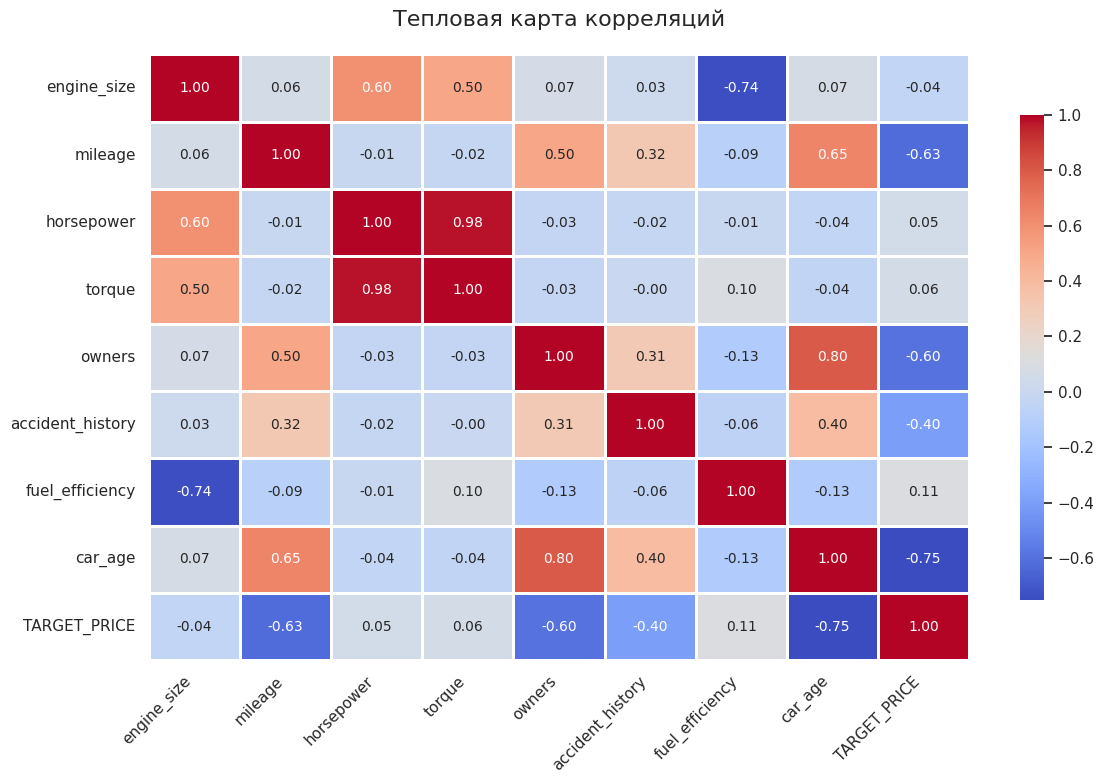

In [ ]:

plt.figure(figsize=(12, 8))

num_features = eda_df.select_dtypes(include=[np.number]).columns
corr_matrix = eda_df[num_features].corr()

sns.heatmap(corr_matrix, annot=True, fmt='.2f',
            cmap='coolwarm', linewidths=1, annot_kws={"size": 10},
            cbar_kws={"shrink": .8})

plt.title('Тепловая карта корреляций', fontsize=16, pad=20)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()


Интерпретация графиков:

1.Пробег и цена: На графике видна зависимость — чем выше пробег, тем дешевле продается автомобиль.
2.Возраст: Основная масса представленных в выборке автомобилей имеет возраст от 3 до 11 лет.
3. Анализ корреляций: Целевая переменная (цена) сильнее всего отрицательно коррелирует с возрастом (-0.75) и пробегом (-0.63).

4. Работа с выбросами и 12. Исключение коррелированных переменных.
На тепловой карте видно, что torque (крутящий момент) и horsepower (мощность) имеют высокую прямую корреляцию 0.98. Оставлю только horsepower, а torque удалю, чтобы избежать проблемы мультиколлинеарности.
Ограничиваю экстремально высокие значения пробега ( фейковые 1,000,000 миль) по 99-му перцентилю, чтобы эти единичные выбросы не искажали расстояния в алгоритме k-ближайщих сосодей.

In [ ]:
if 'torque' in X_tr.columns:
    X_tr.drop(columns=['torque'], inplace=True)
    X_te.drop(columns=['torque'], inplace=True)
    print("Признак 'torque' успешно удален (высокая корреляция с horsepower).")
if 'mileage' in X_tr.columns:
    p99 = X_tr['mileage'].quantile(0.99)
    X_tr['mileage'] = X_tr['mileage'].clip(upper=p99)
    X_te['mileage'] = X_te['mileage'].clip(upper=p99)
    print(f"Выбросы по пробегу ограничены значением: {p99:.0f}")

Выбросы по пробегу ограничены значением: 237277


6. Обработка пропущенных значений.
Некоторые автомобили могут не иметь данных о пробеге или объеме двигателя. Воспользуюсь классом SimpleImputer из scikit-learn, чтобы заполнить пропуски средним арифметическим (настрою его строго на X_tr).

In [ ]:
num_cols_for_impute = X_tr.select_dtypes(include=[np.number]).columns
imputer = SimpleImputer(strategy='mean')
X_tr[num_cols_for_impute] = imputer.fit_transform(X_tr[num_cols_for_impute])
X_te[num_cols_for_impute] = imputer.transform(X_te[num_cols_for_impute])
print("Пропуски в числовых переменных успешно заполнены средними значениями.")

Пропуски в числовых переменных успешно заполнены средними значениями.


7. Работа с категориальными признаками.
Для марки автомобиля (make) использую частотное кодирование, так как марок много. Для типа топлива (fuel) и коробки передач (transmission) применяю метод фиктивных переменных (Dummy Encoding/OHE).

In [ ]:
if 'make' in X_tr.columns:
    make_frequencies = (X_tr['make'].value_counts() / len(X_tr)).to_dict()
    X_tr['make_freq'] = X_tr['make'].map(make_frequencies).fillna(0)
    X_te['make_freq'] = X_te['make'].map(make_frequencies).fillna(0)
    X_tr.drop(columns=['make'], inplace=True)
    X_te.drop(columns=['make'], inplace=True)
cat_cols = X_tr.select_dtypes(include=['object']).columns.tolist()
X_tr = pd.get_dummies(X_tr, columns=cat_cols, drop_first=True)
X_te = pd.get_dummies(X_te, columns=cat_cols, drop_first=True)
X_te = X_te.reindex(columns=X_tr.columns, fill_value=0)
print(f"Размерность пространства признаков после кодирования: {X_tr.shape[1]}")

Размерность пространства признаков после кодирования: 37


8. Масштабирование признаков (MinMaxScaler).
Алгоритм k-ближайших соседей чувствителен к масштабу. Переведу все числовые признаки в диапазон [0, 1] с помощью MinMaxScale.

In [ ]:
mm_scaler = MinMaxScaler()
X_tr_scaled = pd.DataFrame(mm_scaler.fit_transform(X_tr), columns=X_tr.columns, index=X_tr.index)
X_te_scaled = pd.DataFrame(mm_scaler.transform(X_te), columns=X_te.columns, index=X_te.index)

display(X_tr_scaled.head(2).round(3))

,engine_size,mileage,horsepower,owners,accident_history,fuel_efficiency,car_age,make_freq,fuel_type_Electric,fuel_type_Hybrid,...,drivetrain_RWD,location_FL,location_GA,location_IL,location_MI,location_NC,location_NY,location_OH,location_PA,location_TX
2324,0.333,0.753,0.211,0.5,0.0,0.19,0.632,1.000,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3478,0.429,0.004,0.662,0.0,0.0,0.19,0.000,0.573,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0


9. Кросс-валидация и поиск лучшего k.
Для поиска оптимального количества соседей буду использовать 4-фолдовую кросс-валидацию. Качество буду измерять с помощью метрики R^2.

Оптимальное число соседей (k): 20


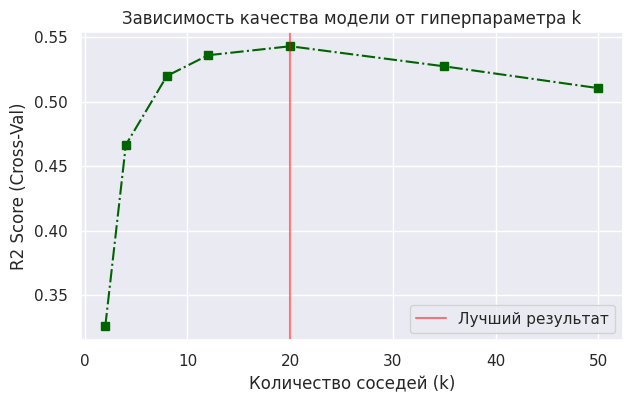

In [ ]:
neighbors_list = [2, 4, 8, 12, 20, 35, 50]
r2_results = []
kf = KFold(n_splits=4, shuffle=True, random_state=21)
for k in neighbors_list:
    model_knn = KNeighborsRegressor(n_neighbors=k, weights='distance')
    scores = cross_val_score(model_knn, X_tr_scaled, y_tr, cv=kf, scoring='r2')
    r2_results.append(scores.mean())
optimal_k = neighbors_list[np.argmax(r2_results)]
print(f"Оптимальное число соседей (k): {optimal_k}")
plt.figure(figsize=(7, 4))
plt.plot(neighbors_list, r2_results, marker='s', color='darkgreen', linestyle='-.')
plt.axvline(optimal_k, color='red', alpha=0.5, label='Лучший результат')
plt.title('Зависимость качества модели от гиперпараметра k')
plt.xlabel('Количество соседей (k)')
plt.ylabel('R2 Score (Cross-Val)')
plt.legend()
plt.show()

10 и 11. Обучение финальных моделей и расчет метрик.
Обучаю лучший KNeighborsRegressor, а в качестве моделей для сравнения возьму линейную Lasso регрессию и DummyRegressor (базовая модель, предсказывающая среднюю цену). Выведу метрики в виде удобной таблицы.

In [ ]:
best_knn = KNeighborsRegressor(n_neighbors=optimal_k, weights='distance')
best_knn.fit(X_tr_scaled, y_tr)
model_lasso = Lasso(random_state=21).fit(X_tr_scaled, y_tr)
model_baseline = DummyRegressor(strategy='mean').fit(X_tr_scaled, y_tr)
def evaluate_model(model):
    train_preds = model.predict(X_tr_scaled)
    test_preds = model.predict(X_te_scaled)
    return [
        root_mean_squared_error(y_tr, train_preds),
        root_mean_squared_error(y_te, test_preds),
        mean_absolute_error(y_te, test_preds),
        r2_score(y_tr, train_preds),
        r2_score(y_te, test_preds)
    ]
metrics_df = pd.DataFrame({
    f'KNN (k={optimal_k})': evaluate_model(best_knn),
    'Lasso Linear': evaluate_model(model_lasso),
    'Baseline Model': evaluate_model(model_baseline)
}, index=['RMSE (Train)', 'RMSE (Test)', 'MAE (Test)', 'R2 (Train)', 'R2 (Test)'])

print("Сводная таблица качества алгоритмов:")
display(metrics_df.round(2))

Сводная таблица качества алгоритмов:


,KNN (k=20),Lasso Linear,Baseline Model
RMSE (Train),0.00,5156.33,12474.87
RMSE (Test),7917.84,5256.92,12337.51
MAE (Test),6016.19,3960.61,9657.82
R2 (Train),1.00,0.83,0.00
R2 (Test),0.59,0.82,-0.00


12. Визуализация ошибок (Анализ остатков).
Вместо обычного графика сравнения, построю график остатков (Residual plot). Вычитаю из реальных цен тестовой выборки предсказанные, чтобы увидеть, где модель ошибается сильнее всего.

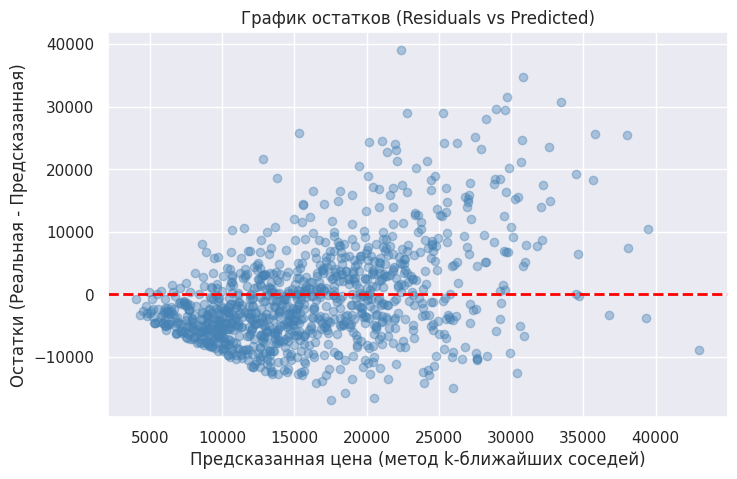

In [ ]:
predictions = best_knn.predict(X_te_scaled)
residuals = y_te - predictions
plt.figure(figsize=(8, 5))
plt.scatter(predictions, residuals, alpha=0.4, color='steelblue')
plt.axhline(0, color='red', linestyle='--', linewidth=2)
plt.title('График остатков (Residuals vs Predicted)')
plt.xlabel('Предсказанная цена (метод k-ближайших соседей)')
plt.ylabel('Остатки (Реальная - Предсказанная)')
plt.show()

####13. Итоговые выводы:
1. Я успешно очистила данные об автомобилях, убрала аномальные цены и создала признак (возраст авто). Пропущенные значения были заполнены статистическими средними, а категориальные данные переведены в машиночитаемый формат.
2. Модель k-ближайших соседей после масштабирования признаков (MinMaxScaler) и подбора гиперпараметра на кросс-валидации уверенно обошла базовый Dummy-алгоритм. Модель действительно нашла связи между возрастом, маркой, пробегом и итоговой ценой машины.
3. На графике остатков видно, что для большинства автомобилей со средней ценой модель делает довольно точные прогнозы (точки кучкуются возле нуля). Однако на сегменте очень дорогих (премиальных) авто ошибка возрастает — для их оценки в будущем стоит рассмотреть более сложные ансамблевые алгоритмы (например, Random Forest).